## Section 1: Setup

In [4]:
import os, json, random, copy
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

RETRAIN = False  # False = load saved weights; True = retrain from scratch

PyTorch: 2.11.0+cu130 | Device: cuda


## Section 2: Data

In [5]:
DATA_DIR = (
    "/kaggle/input/datasets/peaceedogun/"
    "nigerian-foods-and-snacks-multiclass/"
    "data_train_test/data_train_test"
)
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

class_names = sorted(
    d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))
)
class_to_idx = {name: i for i, name in enumerate(class_names)}

# Collect training images. The inner listdir is deliberately NOT sorted,
# to reproduce the original order (and therefore the original split).
image_paths, labels = [], []
for class_name in class_names:
    class_dir = os.path.join(TRAIN_DIR, class_name)
    for filename in os.listdir(class_dir):
        if filename.lower().endswith(IMAGE_EXTS):
            image_paths.append(os.path.join(class_dir, filename))
            labels.append(class_name)

assert len(class_names) == 18, "Expected 18 classes"
print("Training-pool images:", len(image_paths))

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels, test_size=0.20, random_state=42, stratify=labels
)

# Use the frozen split if the manifest is available
MANIFEST = "/kaggle/input/datasets/musaahmedoriabure/split-manifest/split_manifest.json"
if os.path.exists(MANIFEST):
    with open(MANIFEST) as f:
        m = json.load(f)
    same = (m["val_paths"] == val_paths) and (m["train_paths"] == train_paths)
    print("Rebuilt split identical to original:", same)
    train_paths, train_labels = m["train_paths"], m["train_labels"]
    val_paths, val_labels     = m["val_paths"],   m["val_labels"]
else:
    print("No manifest found; using the rebuilt split (verify accuracy later!)")

print("Train:", len(train_paths), "| Val:", len(val_paths))

Training-pool images: 5947
Rebuilt split identical to original: True
Train: 4757 | Val: 1190


## Section 3: Preprocessing, dataset, loaders

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Baseline CNN: 128x128, no normalization (as originally trained)
baseline_train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
])
baseline_eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

# MobileNetV2: 224x224 with ImageNet normalization
mobilenet_train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
mobilenet_eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FoodDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, class_to_idx[self.labels[i]]

def make_loader(paths, labels, tf, shuffle):
    return DataLoader(FoodDataset(paths, labels, tf),
                      batch_size=32, shuffle=shuffle, num_workers=2)

baseline_train_loader  = make_loader(train_paths, train_labels, baseline_train_tf,  True)
baseline_val_loader    = make_loader(val_paths,   val_labels,   baseline_eval_tf,   False)
mobilenet_train_loader = make_loader(train_paths, train_labels, mobilenet_train_tf, True)
mobilenet_val_loader   = make_loader(val_paths,   val_labels,   mobilenet_eval_tf,  False)

x, _ = next(iter(baseline_train_loader));  print("Baseline batch:", x.shape)
x, _ = next(iter(mobilenet_train_loader)); print("MobileNet batch:", x.shape)
print("Batches:", len(baseline_train_loader), "train |", len(baseline_val_loader), "val")

Baseline batch: torch.Size([32, 3, 128, 128])
MobileNet batch: torch.Size([32, 3, 224, 224])
Batches: 149 train | 38 val


## Section 4: Baseline CNN

In [7]:
class FoodCNN(nn.Module):
    def __init__(self, num_classes=18):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += images.size(0)
    return total_loss / n, correct / n   # accuracy as a fraction (0 to 1)

baseline = FoodCNN(num_classes=18).to(device)
criterion = nn.CrossEntropyLoss()
print("Parameters:", f"{sum(p.numel() for p in baseline.parameters()):,}")

Parameters: 8,486,738


### train or load

In [8]:
BASELINE_CKPT = "/kaggle/input/datasets/musaahmedoriabure/my-model-after-5-epochs/food_cnn_checkpoint.pth"

if RETRAIN:
    optimizer = optim.Adam(baseline.parameters(), lr=0.001)
    baseline_history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(5):
        baseline.train()
        tl, ta = run_epoch(baseline, baseline_train_loader, criterion, optimizer)
        baseline.eval()
        vl, va = run_epoch(baseline, baseline_val_loader, criterion)
        for k, v in zip(baseline_history, (tl, ta, vl, va)):
            baseline_history[k].append(v)
        print(f"Epoch {epoch+1}: train {tl:.4f}/{ta:.2%} | val {vl:.4f}/{va:.2%}")
else:
    # weights_only=False is fine for your own checkpoint; never use it on untrusted files
    ckpt = torch.load(BASELINE_CKPT, map_location=device, weights_only=False)
    baseline.load_state_dict(ckpt["model_state_dict"])
    baseline_history = ckpt["history"]
    print("Loaded baseline checkpoint (epoch", ckpt["epoch"], ")")

Loaded baseline checkpoint (epoch 5 )


### verify and plot

Baseline val loss 1.3905 | val acc 58.40%   (history says 58.40%)


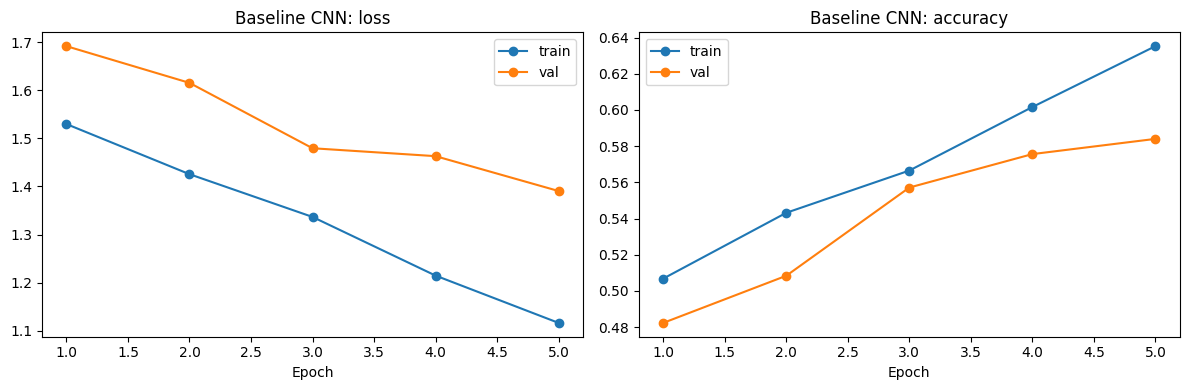

In [9]:
baseline.eval()
vl, va = run_epoch(baseline, baseline_val_loader, criterion)
print(f"Baseline val loss {vl:.4f} | val acc {va:.2%}   (history says {baseline_history['val_accuracy'][-1]:.2%})")

ep = range(1, len(baseline_history["train_loss"]) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ep, baseline_history["train_loss"], marker="o", label="train")
plt.plot(ep, baseline_history["val_loss"], marker="o", label="val")
plt.title("Baseline CNN: loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(ep, baseline_history["train_accuracy"], marker="o", label="train")
plt.plot(ep, baseline_history["val_accuracy"], marker="o", label="val")
plt.title("Baseline CNN: accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.show()

## Section 5: MobileNetV2 transfer learning(v1)

In [14]:
def build_mobilenet(pretrained):
    weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
    m = models.mobilenet_v2(weights=weights)
    m.classifier[1] = nn.Linear(1280, 18)
    return m.to(device)

def freeze_backbone(model, unfreeze_from=None):
    """Freeze all feature blocks; optionally unfreeze blocks[unfreeze_from:]. Classifier is always trainable."""
    for p in model.features.parameters():
        p.requires_grad = False
    if unfreeze_from is not None:
        for block in model.features[unfreeze_from:]:
            for p in block.parameters():
                p.requires_grad = True
    for p in model.classifier.parameters():
        p.requires_grad = True

def set_train_mode(model, n_frozen_blocks):
    """Train mode, except the first n blocks stay in eval so their BatchNorm statistics don't drift."""
    model.train()
    for block in model.features[:n_frozen_blocks]:
        block.eval()

def count_trainable(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return f"{trainable:,} of {total:,} ({100 * trainable / total:.1f}%)"

### train or load v1

In [13]:
V1_PATH = "/kaggle/input/datasets/musaahmedoriabure/mobile-vnet-classifier/mobilenetv2_nigerian_food_v1.pth"

mobilenet = build_mobilenet(pretrained=RETRAIN)
freeze_backbone(mobilenet)
print("Trainable:", count_trainable(mobilenet))

if RETRAIN:
    optimizer = optim.Adam(mobilenet.classifier.parameters(), lr=0.001)
    history_v1 = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(5):
        set_train_mode(mobilenet, n_frozen_blocks=19)   # whole backbone frozen
        tl, ta = run_epoch(mobilenet, mobilenet_train_loader, criterion, optimizer)
        mobilenet.eval()
        vl, va = run_epoch(mobilenet, mobilenet_val_loader, criterion)
        for k, v in zip(history_v1, (tl, ta, vl, va)):
            history_v1[k].append(v)
        print(f"Epoch {epoch+1}: train {tl:.4f}/{ta:.2%} | val {vl:.4f}/{va:.2%}")
    torch.save(mobilenet.state_dict(), "/kaggle/working/mobilenetv2_nigerian_food_v1.pth")
else:
    mobilenet.load_state_dict(torch.load(V1_PATH, map_location=device))
    # Transcribed from the original run's printed output (not recomputed)
    history_v1 = {
        "train_loss":     [1.5819, 1.1037, 0.9152, 0.7985, 0.7331],
        "train_accuracy": [0.6281, 0.7295, 0.7604, 0.7913, 0.8087],
        "val_loss":       [1.2941, 1.0364, 0.9244, 0.8417, 0.7806],
        "val_accuracy":   [0.6748, 0.7403, 0.7496, 0.7739, 0.7916],
    }
    print("Loaded v1 weights")

Trainable: 23,058 of 2,246,930 (1.0%)
Loaded v1 weights


### the gate

In [15]:
mobilenet.eval()
vl, va = run_epoch(mobilenet, mobilenet_val_loader, criterion)
print(f"v1 val loss {vl:.4f} | val acc {va:.2%}   (expected 0.7806 | 79.16%)")

v1 val loss 0.7806 | val acc 79.16%   (expected 0.7806 | 79.16%)


## Section 6: Fine-tuning(v2)

In [17]:
import copy

V2_PATH = "/kaggle/input/datasets/musaahmedoriabure/mobilevnet2-fine/mobilenetv2_nigerian_food_v2.pth"

finetuned = build_mobilenet(pretrained=False)
finetuned.load_state_dict(mobilenet.state_dict())    # start from v1
freeze_backbone(finetuned, unfreeze_from=17)
print("Trainable:", count_trainable(finetuned))      # expect 909,138 of 2,246,930 (40.5%)

if RETRAIN:
    optimizer_ft = optim.Adam([
        {"params": finetuned.features[17:].parameters(), "lr": 1e-4},
        {"params": finetuned.classifier.parameters(),    "lr": 5e-4},
    ])
    finetuned.eval()
    _, best_acc = run_epoch(finetuned, mobilenet_val_loader, criterion)
    print(f"Before fine-tuning: val acc {best_acc:.2%}")   # should be about 79.16%
    best_state = copy.deepcopy(finetuned.state_dict())
    history_v2 = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(5):
        set_train_mode(finetuned, n_frozen_blocks=17)
        tl, ta = run_epoch(finetuned, mobilenet_train_loader, criterion, optimizer_ft)
        finetuned.eval()
        vl, va = run_epoch(finetuned, mobilenet_val_loader, criterion)
        for k, v in zip(history_v2, (tl, ta, vl, va)):
            history_v2[k].append(v)
        print(f"Epoch {epoch+1}: train {tl:.4f}/{ta:.2%} | val {vl:.4f}/{va:.2%}")
        if va > best_acc:
            best_acc = va
            best_state = copy.deepcopy(finetuned.state_dict())

    finetuned.load_state_dict(best_state)
    torch.save(best_state, "/kaggle/working/mobilenetv2_nigerian_food_v2.pth")
else:
    finetuned.load_state_dict(torch.load(V2_PATH, map_location=device))
    # Transcribed from the original run's printed output (not recomputed)
    history_v2 = {
        "train_loss":     [0.7365, 0.5080, 0.4056, 0.3341, 0.2980],
        "train_accuracy": [0.7902, 0.8581, 0.8829, 0.9062, 0.9165],
        "val_loss":       [0.6353, 0.5764, 0.5191, 0.4920, 0.4793],
        "val_accuracy":   [0.8109, 0.8202, 0.8529, 0.8538, 0.8571],
    }
    print("Loaded v2 weights")

Trainable: 909,138 of 2,246,930 (40.5%)
Loaded v2 weights


In [18]:
finetuned.eval()
vl, va = run_epoch(finetuned, mobilenet_val_loader, criterion)
print(f"v2 val loss {vl:.4f} | val acc {va:.2%}   (expected 0.4793 | 85.71%)")

v2 val loss 0.4793 | val acc 85.71%   (expected 0.4793 | 85.71%)


## Section 7: Validation analysis

In [19]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    trues, preds = [], []
    for images, labels in loader:
        preds.extend(model(images.to(device)).argmax(1).cpu().numpy())
        trues.extend(labels.numpy())
    return np.array(trues), np.array(preds)

y_true, y_pred_v1 = predict(mobilenet,  mobilenet_val_loader)   # v1
_,      y_pred_v2 = predict(finetuned,  mobilenet_val_loader)   # v2

print("v1 acc:", round((y_true == y_pred_v1).mean(), 4), "| errors:", (y_true != y_pred_v1).sum())
print("v2 acc:", round((y_true == y_pred_v2).mean(), 4), "| errors:", (y_true != y_pred_v2).sum())

v1 acc: 0.7916 | errors: 248
v2 acc: 0.8571 | errors: 170



### learning curves for all three models

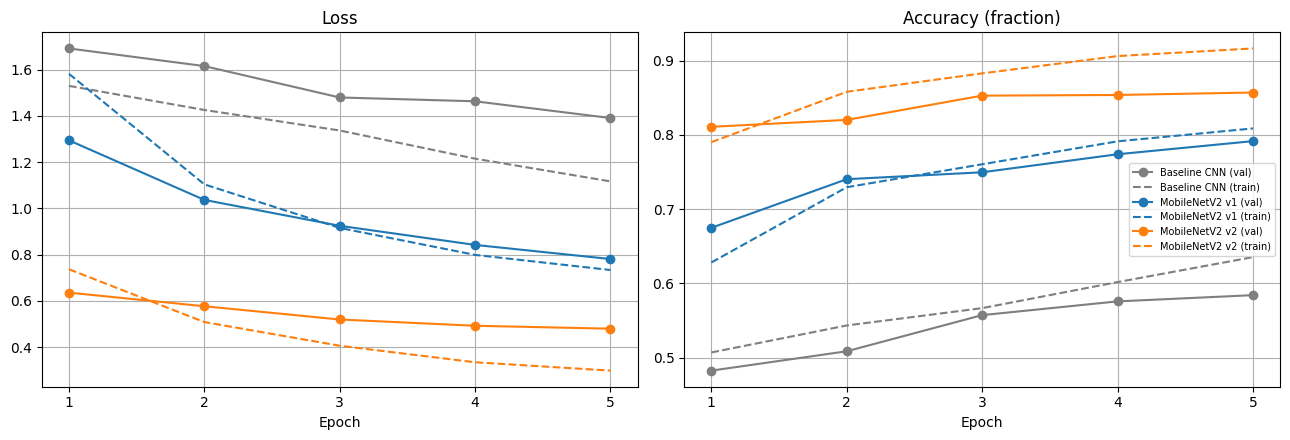

In [20]:
runs = {"Baseline CNN": baseline_history, "MobileNetV2 v1": history_v1, "MobileNetV2 v2": history_v2}
colors = ["tab:gray", "tab:blue", "tab:orange"]
ep = range(1, 6)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, h), c in zip(runs.items(), colors):
    axes[0].plot(ep, h["val_loss"],   color=c, marker="o", label=f"{name} (val)")
    axes[0].plot(ep, h["train_loss"], color=c, ls="--",    label=f"{name} (train)")
    axes[1].plot(ep, h["val_accuracy"],   color=c, marker="o", label=f"{name} (val)")
    axes[1].plot(ep, h["train_accuracy"], color=c, ls="--",    label=f"{name} (train)")
axes[0].set_title("Loss"); axes[1].set_title("Accuracy (fraction)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.set_xticks(list(ep)); ax.grid(True)
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("/kaggle/working/learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### confusion matrix and report for v2(validation)

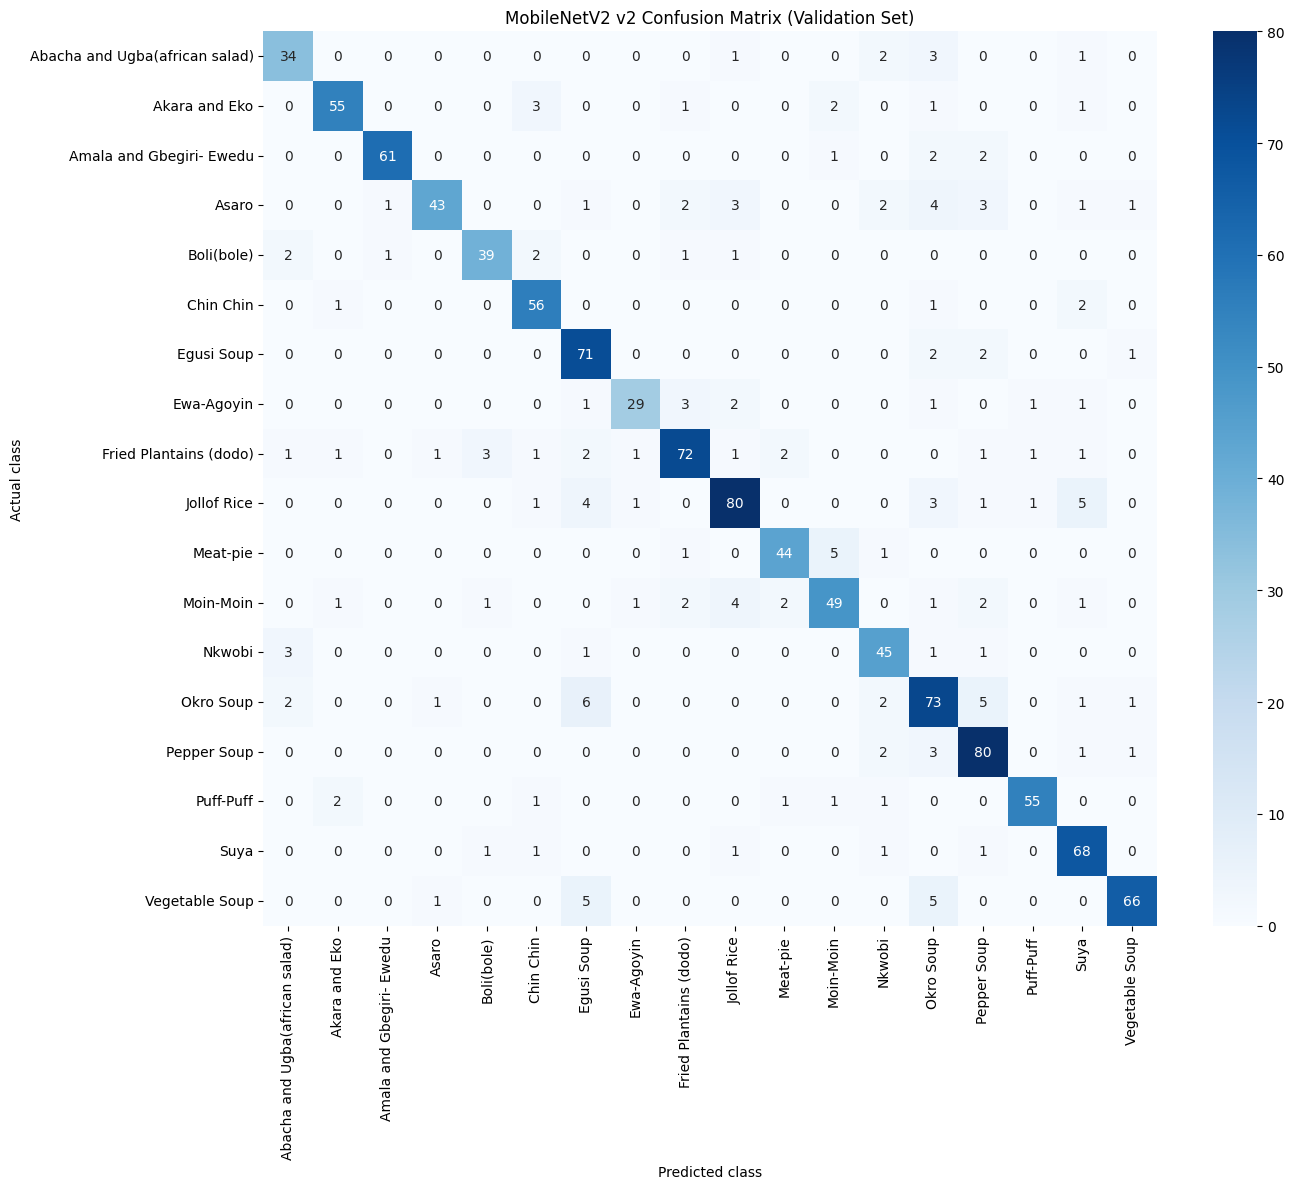

                                precision    recall  f1-score   support

Abacha and Ugba(african salad)      0.810     0.829     0.819        41
                 Akara and Eko      0.917     0.873     0.894        63
      Amala and Gbegiri- Ewedu      0.968     0.924     0.946        66
                         Asaro      0.935     0.705     0.804        61
                    Boli(bole)      0.886     0.848     0.867        46
                     Chin Chin      0.862     0.933     0.896        60
                    Egusi Soup      0.780     0.934     0.850        76
                    Ewa-Agoyin      0.906     0.763     0.829        38
        Fried Plantains (dodo)      0.878     0.818     0.847        88
                   Jollof Rice      0.860     0.833     0.847        96
                      Meat-pie      0.898     0.863     0.880        51
                     Moin-Moin      0.845     0.766     0.803        64
                        Nkwobi      0.804     0.882     0.841  

In [21]:
cm = confusion_matrix(y_true, y_pred_v2)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class"); plt.ylabel("Actual class")
plt.title("MobileNetV2 v2 Confusion Matrix (Validation Set)")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix_val_v2.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_true, y_pred_v2, target_names=class_names, digits=3))

### error grids, now with no hidden globals

v1 Okro->Pepper: 11 | v2 fixed: 7
v1 Asaro missed: 23 | v2 fixed: 10


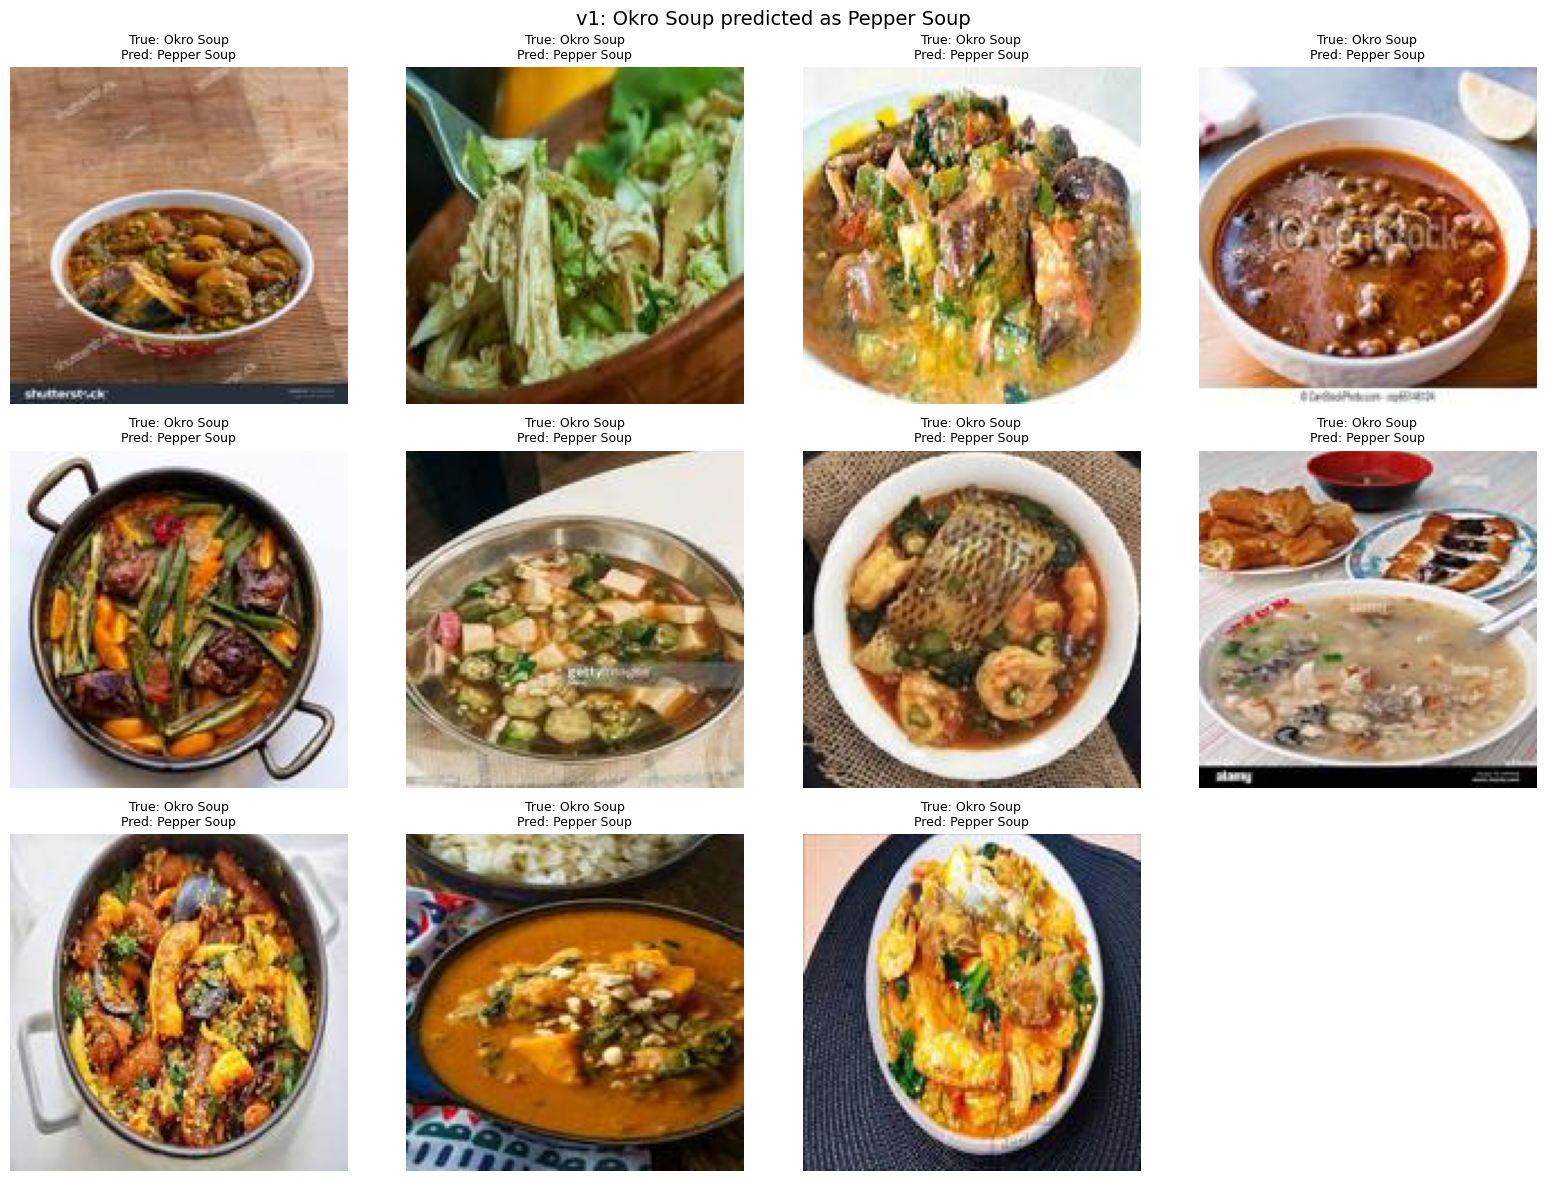

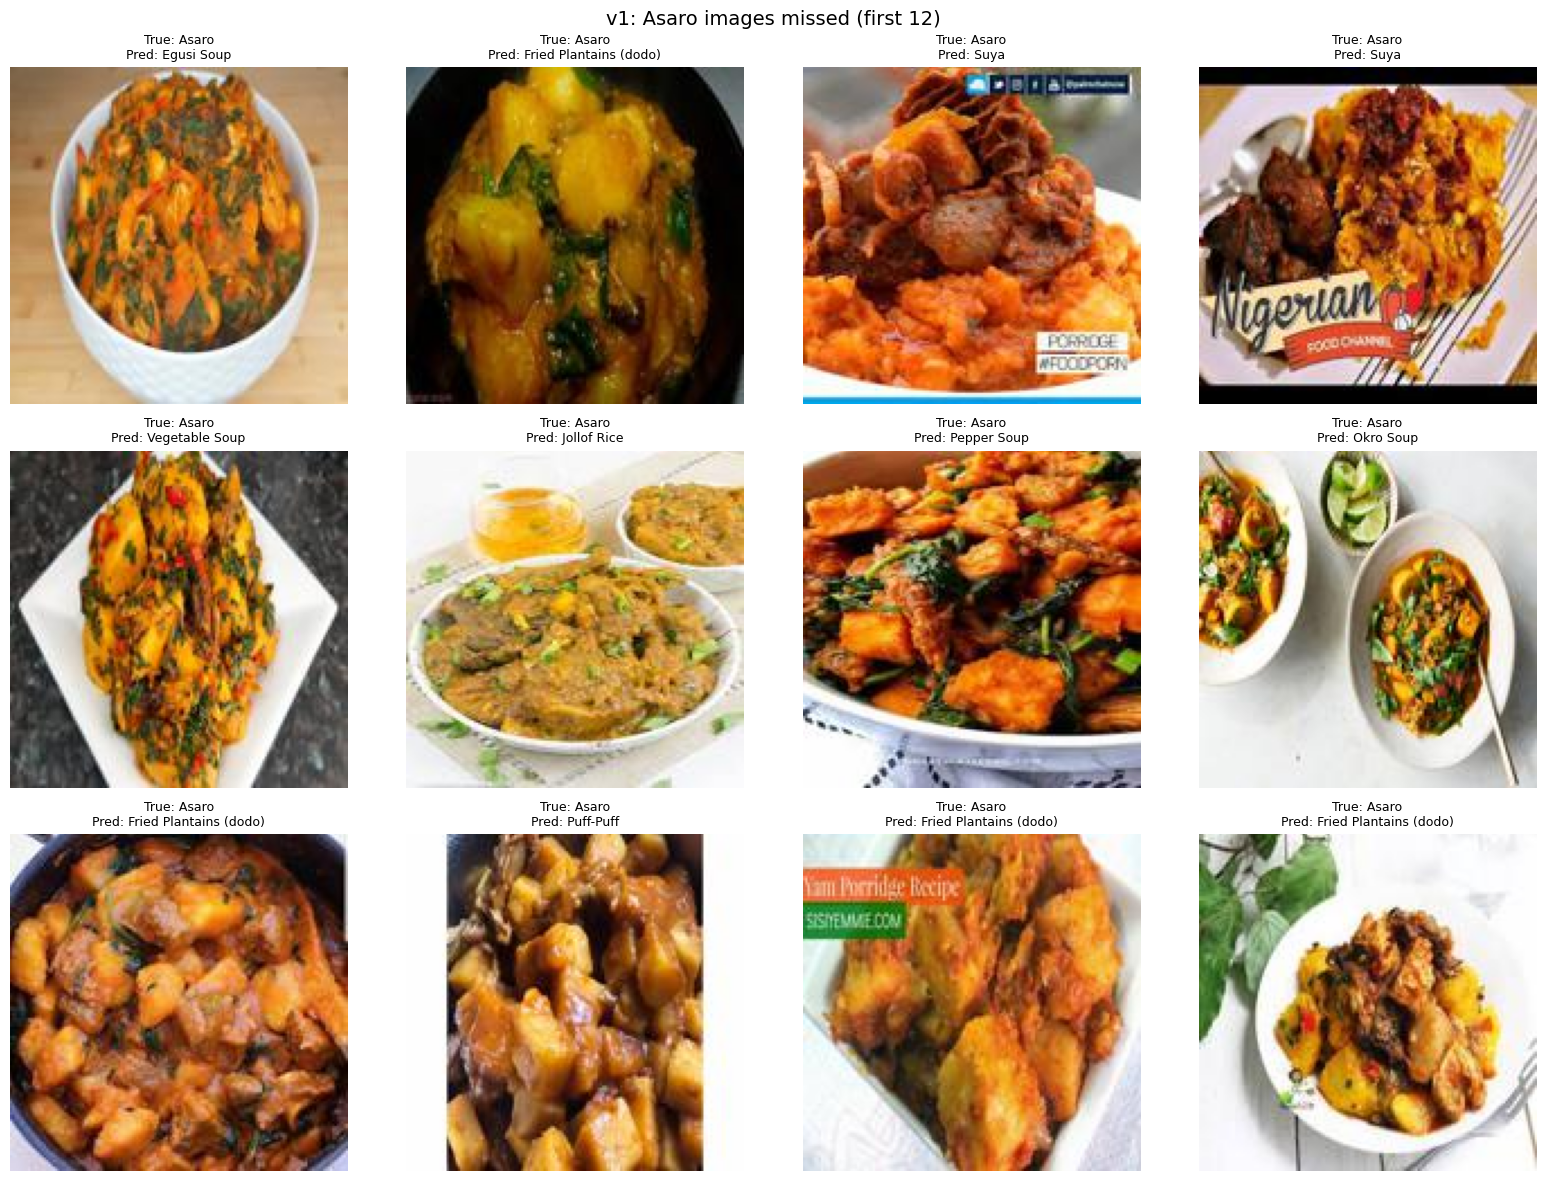

In [22]:
def show_errors(indices, y_true, y_pred, dataset, title, cols=4):
    rows = (len(indices) + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))
    for k, i in enumerate(indices):
        img = Image.open(dataset.paths[i]).convert("RGB")
        plt.subplot(rows, cols, k + 1)
        plt.imshow(img); plt.axis("off")
        plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}", fontsize=9)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

val_ds = mobilenet_val_loader.dataset
okro, pepper, asaro = (class_to_idx[n] for n in ["Okro Soup", "Pepper Soup", "Asaro"])

okro_as_pepper = np.where((y_true == okro) & (y_pred_v1 == pepper))[0]
asaro_missed   = np.where((y_true == asaro) & (y_pred_v1 != asaro))[0]
print("v1 Okro->Pepper:", len(okro_as_pepper), "| v2 fixed:", (y_pred_v2[okro_as_pepper] == okro).sum())
print("v1 Asaro missed:", len(asaro_missed),   "| v2 fixed:", (y_pred_v2[asaro_missed]   == asaro).sum())

show_errors(okro_as_pepper, y_true, y_pred_v1, val_ds, "v1: Okro Soup predicted as Pepper Soup")
show_errors(asaro_missed[:12], y_true, y_pred_v1, val_ds, "v1: Asaro images missed (first 12)")

In [23]:
fixed  = int(((y_pred_v1 != y_true) & (y_pred_v2 == y_true)).sum())
broken = int(((y_pred_v1 == y_true) & (y_pred_v2 != y_true)).sum())
v1_err = int((y_pred_v1 != y_true).sum())

print(f"v1 errors: {v1_err} | fixed by v2: {fixed} ({fixed / v1_err:.0%})")
print(f"v1 correct: {len(y_true) - v1_err} | broken by v2: {broken}")
print(f"Net change in errors: {broken - fixed}")

v1 errors: 248 | fixed by v2: 101 (41%)
v1 correct: 942 | broken by v2: 23
Net change in errors: -78


In [24]:
import hashlib

def file_md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

test_paths = [os.path.join(TEST_DIR, c, f)
              for c in class_names
              for f in sorted(os.listdir(os.path.join(TEST_DIR, c)))]

h_train = {file_md5(p) for p in train_paths}
print("Val images identical to a train image: ", sum(file_md5(p) in h_train for p in val_paths))
print("Test images identical to a train image:", sum(file_md5(p) in h_train for p in test_paths))

Val images identical to a train image:  139
Test images identical to a train image: 19


In [25]:
hash_of = {p: file_md5(p) for p in train_paths + val_paths}   # about 6,000 files, may take a minute

train_hash_labels = {}
for p, l in zip(train_paths, train_labels):
    train_hash_labels.setdefault(hash_of[p], set()).add(l)

val_dup = np.array([hash_of[p] in train_hash_labels for p in val_paths])
conflicts = sum(1 for p, l in zip(val_paths, val_labels)
                if hash_of[p] in train_hash_labels and l not in train_hash_labels[hash_of[p]])

print("Duplicate val images:", val_dup.sum(), "of", len(val_dup))
print("Duplicates whose label differs from the train copy:", conflicts)
print("Redundant files inside the training split:",
      len(train_paths) - len({hash_of[p] for p in train_paths}))

_, y_pred_base = predict(baseline, baseline_val_loader)

print(f"\n{'Model':10s} {'duplicates':>11s} {'unique only':>12s} {'overall':>9s}")
for name, yp in [("Baseline", y_pred_base), ("v1", y_pred_v1), ("v2", y_pred_v2)]:
    print(f"{name:10s} {(yp[val_dup] == y_true[val_dup]).mean():11.2%} "
          f"{(yp[~val_dup] == y_true[~val_dup]).mean():12.2%} {(yp == y_true).mean():9.2%}")

Duplicate val images: 139 of 1190
Duplicates whose label differs from the train copy: 2
Redundant files inside the training split: 311

Model       duplicates  unique only   overall
Baseline        83.45%       55.09%    58.40%
v1              88.49%       77.93%    79.16%
v2              94.24%       84.59%    85.71%


## Section 8: Final test evaluation

In [28]:
test_labels = [os.path.basename(os.path.dirname(p)) for p in test_paths]
assert set(test_labels) == set(class_names)

test_loader = make_loader(test_paths, test_labels, mobilenet_eval_tf, shuffle=False)
print("Test images:", len(test_paths))

# One-time evaluation of the FINAL model (v2). No model changes after this cell.
test_true, test_pred = predict(finetuned, test_loader)
print("Test accuracy:", f"{(test_true == test_pred).mean():.2%}")        # expect 87.53%

test_dup = np.array([file_md5(p) in train_hash_labels for p in test_paths])
print("Test images identical to a train image:", test_dup.sum())          # expect 19
print(f"Accuracy on those duplicates: {(test_pred[test_dup] == test_true[test_dup]).mean():.2%}")
n_unique = int((~test_dup).sum())
print(f"Accuracy excluding duplicates ({n_unique} images): "
      f"{(test_pred[~test_dup] == test_true[~test_dup]).mean():.2%}")
print(classification_report(test_true, test_pred, target_names=class_names, digits=3))

Test images: 1492
Test accuracy: 87.53%
Test images identical to a train image: 19
Accuracy on those duplicates: 94.74%
Accuracy excluding duplicates (1473 images): 87.44%
                                precision    recall  f1-score   support

Abacha and Ugba(african salad)      0.875     0.824     0.848        51
                 Akara and Eko      0.940     0.797     0.863        79
      Amala and Gbegiri- Ewedu      0.974     0.892     0.931        83
                         Asaro      0.922     0.766     0.837        77
                    Boli(bole)      0.963     0.881     0.920        59
                     Chin Chin      0.821     0.877     0.848        73
                    Egusi Soup      0.800     0.917     0.854        96
                    Ewa-Agoyin      0.846     0.917     0.880        48
        Fried Plantains (dodo)      0.971     0.909     0.939       110
                   Jollof Rice      0.851     0.858     0.855       120
                      Meat-pie     

In [31]:
seen, redundant = set(), Counter()
for p, l in zip(train_paths, train_labels):
    h = hash_of[p]
    if h in seen:
        redundant[l] += 1
    else:
        seen.add(h)

train_counts = Counter(train_labels)
print(f"{'Class':32s} {'redundant':>9s} {'train':>6s} {'share':>6s}")
for c in class_names:
    print(f"{c:32s} {redundant[c]:9d} {train_counts[c]:6d} {redundant[c] / train_counts[c]:6.1%}")

Class                            redundant  train  share
Abacha and Ugba(african salad)          10    163   6.1%
Akara and Eko                           40    253  15.8%
Amala and Gbegiri- Ewedu                19    262   7.3%
Asaro                                   19    243   7.8%
Boli(bole)                              21    187  11.2%
Chin Chin                               25    240  10.4%
Egusi Soup                               4    304   1.3%
Ewa-Agoyin                              28    153  18.3%
Fried Plantains (dodo)                   4    351   1.1%
Jollof Rice                              0    384   0.0%
Meat-pie                                27    204  13.2%
Moin-Moin                               15    254   5.9%
Nkwobi                                  12    204   5.9%
Okro Soup                               10    362   2.8%
Pepper Soup                             40    346  11.6%
Puff-Puff                               29    247  11.7%
Suya                           

## Section 9: Final artifacts

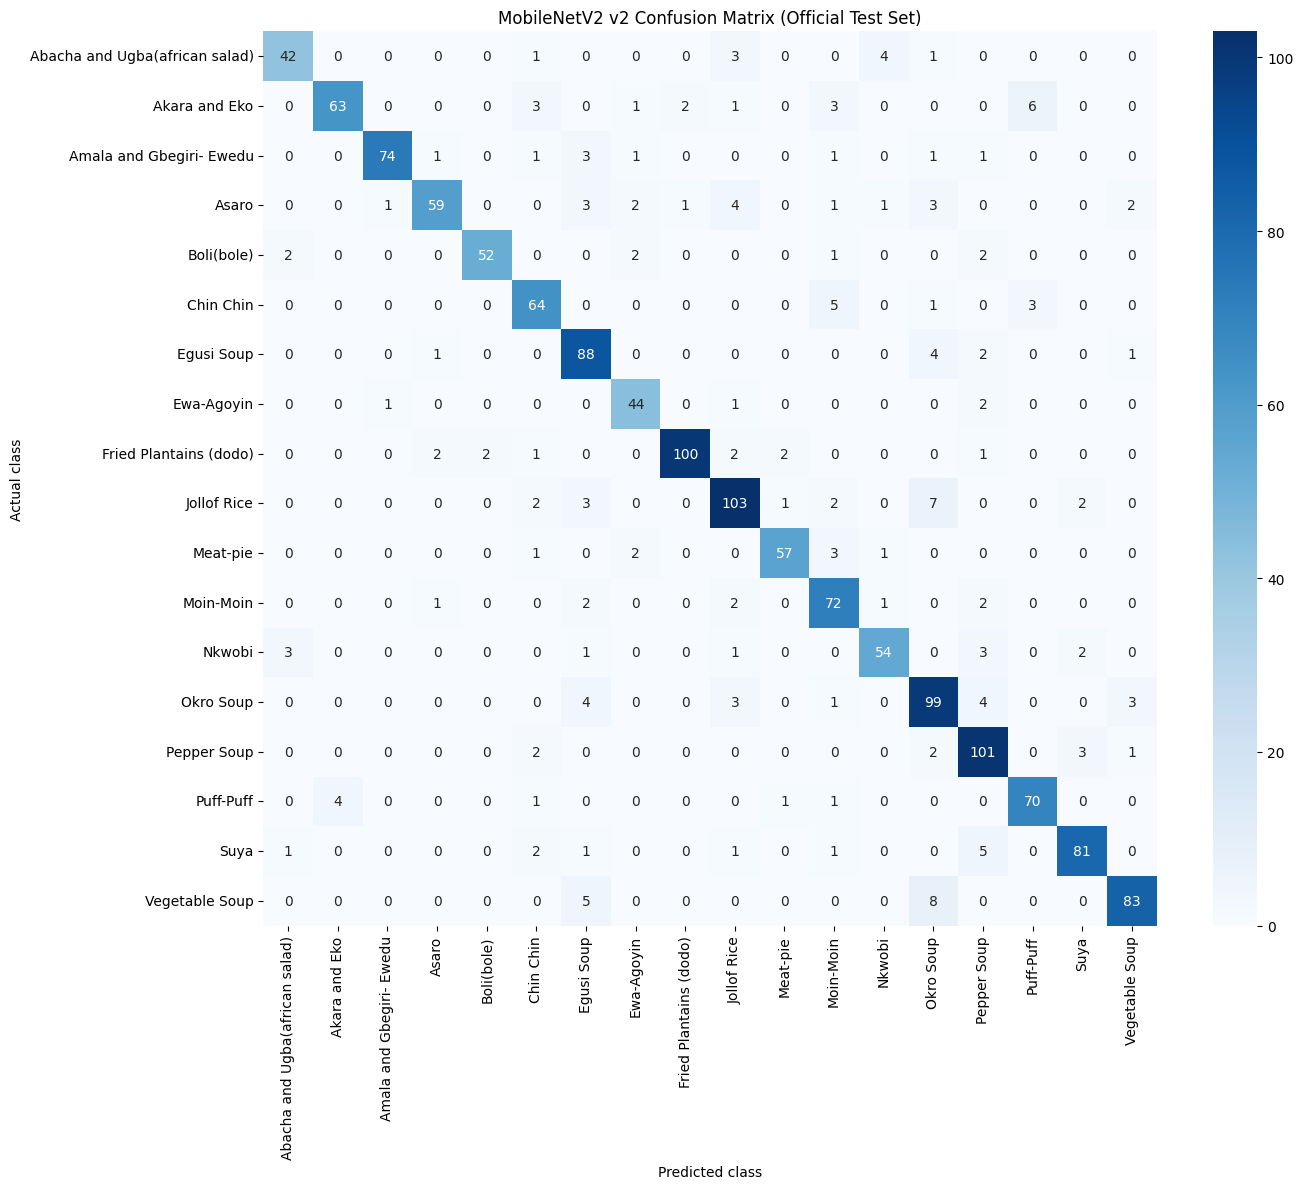

In [32]:
cm_test = confusion_matrix(test_true, test_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class"); plt.ylabel("Actual class")
plt.title("MobileNetV2 v2 Confusion Matrix (Official Test Set)")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

with open("/kaggle/working/test_classification_report.txt", "w") as f:
    f.write(classification_report(test_true, test_pred, target_names=class_names, digits=3))

In [33]:
import shutil

shutil.copy(V1_PATH, "/kaggle/working/mobilenetv2_nigerian_food_v1.pth")
shutil.copy(V2_PATH, "/kaggle/working/mobilenetv2_nigerian_food_v2.pth")
shutil.copy(MANIFEST, "/kaggle/working/split_manifest.json")
with open("/kaggle/working/class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f)

print(sorted(os.listdir("/kaggle/working")))

['.virtual_documents', 'class_to_idx.json', 'confusion_matrix_test.png', 'confusion_matrix_val_v2.png', 'learning_curves.png', 'mobilenetv2_nigerian_food_v1.pth', 'mobilenetv2_nigerian_food_v2.pth', 'split_manifest.json', 'test_classification_report.txt']


In [34]:
def predict_image(path, model=finetuned, k=3):
    model.eval()
    with Image.open(path) as img:
        x = mobilenet_eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    top = probs.topk(k)
    return [(class_names[i], round(float(p), 3)) for p, i in zip(top.values, top.indices)]

for p in random.sample(test_paths, 3):
    print("True:", os.path.basename(os.path.dirname(p)))
    print("Top 3:", predict_image(p), "\n")

True: Suya
Top 3: [('Suya', 0.992), ('Boli(bole)', 0.006), ('Abacha and Ugba(african salad)', 0.001)] 

True: Asaro
Top 3: [('Asaro', 0.849), ('Fried Plantains (dodo)', 0.099), ('Okro Soup', 0.018)] 

True: Akara and Eko
Top 3: [('Chin Chin', 0.465), ('Puff-Puff', 0.21), ('Meat-pie', 0.106)] 

